In [1]:
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'utility')))
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"  
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}

from sklearn.preprocessing      import MinMaxScaler
from keras.models               import Model
from keras.layers               import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D, Concatenate, Lambda, Multiply, Minimum, Maximum, LSTM, Masking
from keras.layers               import GlobalAveragePooling1D, RepeatVector
from keras.constraints          import NonNeg
from preProcessingDataTEP       import PreProcessData
# from matpilotDraw               import MatPlot

import tensorflow           as tf
import numpy                as np
import pandas               as pd
import matplotlib.pyplot    as plt
import random
import warnings
import json

seedNumber          = 805

tf.random.set_seed(seedNumber)
np.random.seed(seedNumber)
random.seed(seedNumber)

warnings.filterwarnings('ignore') 

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]


prePro          = PreProcessData(config=myConfig)
# -----------------------------
# Load and prepare data
# -----------------------------
allWithoutLabel      = ['D feed',                   'E Feed',                   'A Feed',                   'A and C Feed',         'Recycle',              'Purge', 
                        'Separator',                'Stripper',                 'Steam',                    'Reactor Coolant',      'Condenser Coolant',    'Agitator',                 # 12 manipulated variables
                        'msv A Feed',               'msv D Feed',               'msv E Feed',               'msv A and C Feed',     'Recycle Flow',         'Reactor Feed Rate',        # 41 measured variables
                        'Reactor Pressure',         'Reactor Temperature',      'Purge Rate',               'Product Sep Temp', 
                        'Product Sep Pressure',     'Product Sep Underflow',    'Stripper Pressure',        'Reactor Coolant Temp',
                        'Stripper Underflow',       'Stripper Temp',            'Stripper Steam Flow',      'Compressor Work',      
                        'Separator Coolant Temp',   'Component A to Reactor',   'Component B to Reactor',   'Component C to Reactor',
                        'Component D to Reactor',   'Component E to Reactor',   'Component F to Reactor',   'Component A to Purge',
                        'Component B to Purge',     'Component C to Purge',     'Component D to Purge',     'Component E to Purge',
                        'Component F to Purge',     'Component G to Purge',     'Component H to Purge',     'Component D to Product',
                        'Component E to Product',   'Component F to Product',   'Component G to Product',   'Component H to Product',
                        ]     #"rul"

outputDir           = os.path.expanduser(prePro.config["dataDir"])

df                  = prePro.loadDataFromH5Format(dir = outputDir, name="data/teps.h5", case="all", reduceSampleRate = True)
withRULData         = prePro.addRULAndEnvironment(df)

# ---------------------------
# For data
cleanData           = prePro.cleanData(   rawSignal         =   withRULData,
                                        columnName          =   allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = prePro.cleanData(rawSignal            =   cleanData,
                                        columnName          =   prePro.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)


# ==============================
# This function is used to prepare 
# the data
# -----------------------------
def dataHandling(df, idName = 'Id', sensorUsed=None, scaler = None,curEnv = None):
    # -----------------------------
    # Init variables
    # sensorUsed        = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21'] if sensorUsed is None else sensorUsed
    sensorUsed          = allWithoutLabel if sensorUsed is None else sensorUsed
    windowSize          = 30  # Fixed sequence length
    segmentedData       = []
    engineIds           = []
    beginningCycles     = []
    env                 = []

    # -----------------------------
    # Build sliding windows from each engine
    for engId in df[idName].unique():
        dfEngine        = df[df[idName] == engId]
        engineData      = dfEngine[sensorUsed].values
        for start in range(0, len(engineData) - windowSize + 1):
            window = engineData[start : start + windowSize]
            segmentedData.append(window)
            engineIds.append(engId)
            beginningCycles.append(start + 1)
            env.append(curEnv)

    segmentedData           = np.array(segmentedData)  # (N, 30, 14)
    
    # -----------------------------
    # Normalize data
    N, seqLength, numFeatures   = segmentedData.shape                               # Get the shape of the data after converting to numpy array
    xFlat                       = segmentedData.reshape(N * seqLength, numFeatures)
    
    scaler                      = MinMaxScaler() if scaler is None else scaler
    xFlatScaled                 = scaler.fit_transform(xFlat)
    segmentedXScaled            = xFlatScaled.reshape(N, seqLength, numFeatures)
    return segmentedXScaled, engineIds, beginningCycles, env, seqLength, numFeatures





2025-04-27 14:39:29.506529: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-27 14:39:30.228305: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-04-27 14:39:30.228410: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-04-27 14:39:30.228419: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like to use Nvidia GPU with Te

In [2]:
# ------------------------------------
# Data handling before training
# ------------------------------------
xScaled1, engineIds1, beginningCycles1,env1, seqLength, numFeatures     = dataHandling(cleanData[2], curEnv = 1)
yRul, _, _, _, _, _                                                     = dataHandling(cleanData[2], curEnv = 1, sensorUsed=['rul'])  # Get RUL data
yRul1                                                                   = yRul[:,-1,:]  # Get last value of each sequence


xScaled2, engineIds2, beginningCycles2,env2, _, _                       = dataHandling(cleanData[3], curEnv = 2)
yRul, _, _, _, _, _                                                     = dataHandling(cleanData[3], curEnv = 2, sensorUsed=['rul'])  # Get RUL data
yRul2                                                                   = yRul[:,-1,:]  # Get last value of each sequence

xScaled3, engineIds3, beginningCycles3, env3,_, _                       = dataHandling(cleanData[4], curEnv = 3)
yRul, _, _, _, _, _                                                     = dataHandling(cleanData[4], curEnv = 3, sensorUsed=['rul'])  # Get RUL data
yRul3                                                                   = yRul[:,-1,:]  # Get last value of each sequence


allXScaled          = np.concatenate([xScaled1, xScaled2, xScaled3], axis=0)
allYRul             = np.concatenate([yRul1, yRul2, yRul3], axis=0)
allEngineIds        = engineIds1 + engineIds2 + engineIds3
allBeginningCycles  = beginningCycles1 + beginningCycles2 + beginningCycles3
# allEnv              = np.array(env1 + env2 + env3 ).reshape(-1, 1)
allEnv              = np.array(env1 + env2 + env3 )

# ------------------------------------
print(xScaled1.shape, xScaled2.shape, xScaled3.shape)
print(allXScaled.shape)

print(yRul1.shape, yRul2.shape, yRul3.shape)
print(allYRul.shape)

print(len(engineIds1), len(engineIds1), len(engineIds1))
print(len(allEngineIds))

print(len(beginningCycles1), len(beginningCycles2), len(beginningCycles3))
print(len(allBeginningCycles))

print(len(env1), len(env2), len(env3))
print(allEnv.shape)


print(allYRul)
print(allEnv)


(53484, 30, 50) (54130, 30, 50) (46223, 30, 50)
(153837, 30, 50)
(53484, 1) (54130, 1) (46223, 1)
(153837, 1)
53484 53484 53484
153837
53484 54130 46223
153837
53484 54130 46223
(153837,)
[[0.8869863 ]
 [0.88527397]
 [0.88356164]
 ...
 [0.00389864]
 [0.00194932]
 [0.        ]]
[1 1 1 ... 3 3 3]


The shape of rawData is (None, 30, 50)
The shape of probs is (None, 1, 50)
The shape of last layer encoder is (None, 8, 16)
----------------------------------------========
(None, 1, 50)
(None, 30, 50)
----------------------------------------========
(None, 1, 1, 50)
(None, 30, 50)
(None, 30, 50)
['reconstruction', 'RUL_Output']
['ssProbability', 'recon_loss']
Epoch 1/20
The shape of rawData is (None, 30, 50)
The shape of probs is (None, 1, 50)
The shape of rawData is (None, 30, 50)
The shape of probs is (None, 1, 50)
1076/1082 [============================>.] - ETA: 0s - loss: 1327.3257 - RUL_Output_loss: 0.0272 - ssProbability: 1327.2441 - recon_loss: 0.0547The shape of rawData is (None, 30, 50)
The shape of probs is (None, 1, 50)
1082/1082 [==============================] - 12s 9ms/step - loss: 1325.0876 - RUL_Output_loss: 0.0272 - ssProbability: 1324.7877 - recon_loss: 0.0547 - val_loss: 938.1663 - val_RUL_Output_loss: 0.0068 - val_ssProbability: 932.9919 - val_recon_loss: 0.0495
E

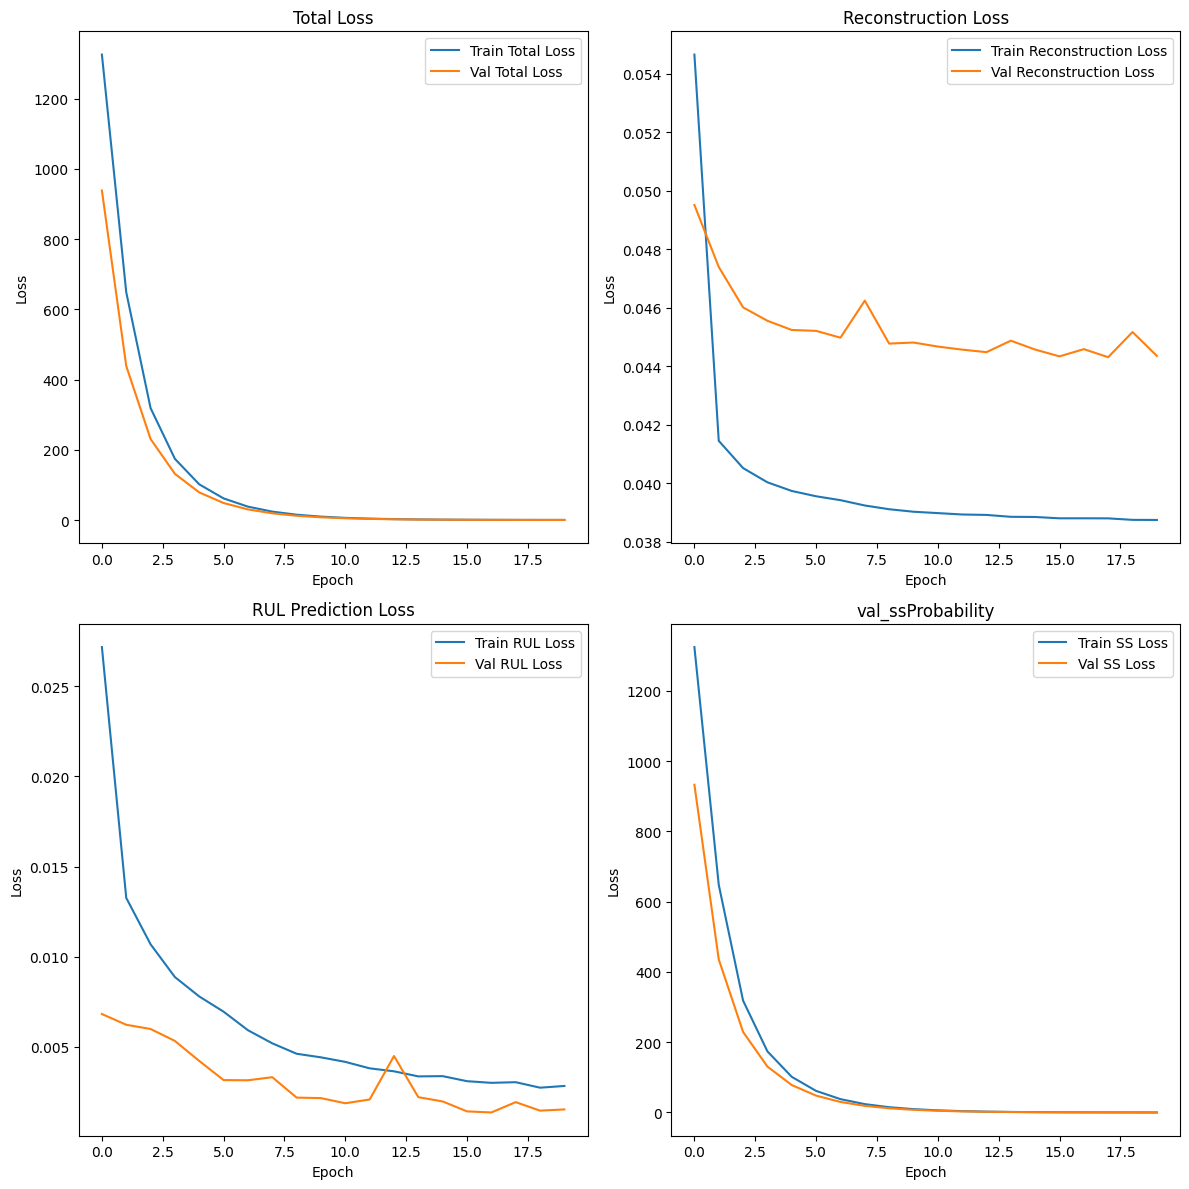

In [29]:
epochTrain = 20
# ==============================
# Sensor selection Class
# ==============================
class SensorSelection(tf.keras.layers.Layer):
    def __init__(self, inFeature = 45, numEnvs = 3):
        '''
        The input size should be (batchSize, timeStep, featureDim)        
        '''
        super(SensorSelection, self).__init__()
        self.mask_logits    = self.add_weight(  shape       =   (numEnvs,inFeature),  # Each mode has different sensor probabilities
                                                initializer =   "random_normal",
                                                trainable   =   True,
                                                name        =   "sensorMask")
                                            
    def call(self,rawData, env):
        # ----------------------------------
        # Select the environment
        # ----------------------------------
        env                 = tf.cast(env-1, tf.int32)                                # Ensure integer type for indexing, and env from 1 to three, so we need index from 0 to 2
        env_mask_logits     = tf.gather(self.mask_logits, env, axis=0)              # (batch_size, num_sensors) each sequence (after split) will have a different env, so env should be a batch (include differnt env to access to the mask)                    
        # print("The shape of mask_logits is", self.mask_logits.shape)
        # print("The shape of env_mask_logits is", env_mask_logits.shape)
        probs               = tf.sigmoid(env_mask_logits)
        # print("The shape of probs is", probs.shape)
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(0.5, probs), tf.float32)
        print("The shape of rawData is", rawData.shape)
        print("The shape of probs is", probs.shape)
        maskedData          = rawData * probs
        # ----------------------------------
        # Add loss function for sensor selection
        sSLoss = tf.reduce_sum(probs * (1 - probs))
        self.add_loss(sSLoss)
        self.add_metric(sSLoss, name="ssProbability", aggregation="mean")
        return maskedData, probs, binary_mask
    
    def getMask(self,):
        probs               = tf.sigmoid(self.mask_logits)   
        random_uniform      = tf.random.uniform(tf.shape(probs))
        binary_mask         = tf.cast(tf.less(0.5, probs), tf.float32) 
        return binary_mask, probs


# ==============================
# Encoder block
# ------------------------------
inputs                      = Input(shape=(seqLength, numFeatures))
inputEnv                    = Input(shape=(1), name="input_env") 
Masking                     = SensorSelection(inFeature = numFeatures, numEnvs   = 3)                            
masked_input, mask_probs, _ = Masking(inputs,inputEnv)
x                           = Conv1D(32, 3, activation='relu', padding='same')(masked_input)
x                           = MaxPooling1D(2, padding='same')(x)
x                           = Conv1D(16, 3, activation='relu', padding='same')(x)
lastAELayer                 = MaxPooling1D(2, padding='same',name='lastAELayer')(x)
x                           = GlobalAveragePooling1D()(lastAELayer)
latent                      = Dense(1, name='latent')(x)  # HI directly here

print("The shape of last layer encoder is", lastAELayer.shape)

# ==============================
# Decoder block
# -----------------------------
x           = Dense((seqLength // 4) * 16, activation='relu')(latent)  # (7 * 16)
x           = Reshape((seqLength // 4, 16))(x)  # Shape: (7, 16)
x           = UpSampling1D(2)(x)  # Shape: (14, 16)
x           = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x           = UpSampling1D(2)(x)  # Shape: (28, 32)
x           = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded     = Conv1D(numFeatures, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)

print("----------------------------------------========")
print(mask_probs.shape)
print(decoded.shape)
print("----------------------------------------========")

print(tf.expand_dims(mask_probs, axis=1).shape)
# masked_decoded  = tf.keras.layers.Multiply(name='reconstruction')([decoded, tf.reshape(mask_probs, (1, 1, -1))])
masked_decoded = tf.keras.layers.Multiply(name='reconstruction')([decoded,mask_probs])

print("=========================================")
print(masked_decoded.shape)
print(masked_input.shape)
print("=========================================")

recon_loss      = tf.reduce_mean(tf.abs(masked_decoded - masked_input))
# ==============================
#   Use RUL as label
# -----------------------------
rulLayer2       = LSTM(16, return_sequences=True)(lastAELayer)
rulLayer3       = LSTM(3, return_sequences=False)(rulLayer2)
flipped_latent  = Lambda(lambda x: -x)(latent)  # force decreasing trend
rulLayer4       = Concatenate(axis=-1)([rulLayer3, latent])

rul             = Dense(1, activation='linear', name="RUL_Output")(rulLayer4)
cnnAEModel      = Model([inputs,inputEnv], outputs=[masked_decoded, rul])


cnnAEModel.add_loss(recon_loss)
cnnAEModel.add_metric(recon_loss, name="recon_loss", aggregation="mean")
cnnAEModel.compile( optimizer    ='adam', 
                    loss         ={ 'RUL_Output': 'mse'},
                    loss_weights ={ 'RUL_Output': 1})  # adjust weights as needed



# ==============================
# Train the model
# ------------------------------

print(cnnAEModel.output_names)  # ['reconstruction']
print(cnnAEModel.metrics_names) # ['loss', 'mae', 'ssProbability']

history = cnnAEModel.fit([allXScaled, allEnv ], {'RUL_Output': allYRul}, epochs=epochTrain, batch_size=128, validation_split=0.1, verbose=1)


print(history.history.keys())


plt.figure(figsize=(12, 12))

plt.subplot(2, 2, 1)
plt.plot(history.history['loss'], label='Train Total Loss')
plt.plot(history.history['val_loss'], label='Val Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Total Loss')
plt.legend()

# --- Plot reconstruction loss ---
plt.subplot(2, 2, 2)
plt.plot(history.history['recon_loss'], label='Train Reconstruction Loss')
plt.plot(history.history['val_recon_loss'], label='Val Reconstruction Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Reconstruction Loss')
plt.legend()

# --- Plot RUL prediction loss ---
plt.subplot(2, 2, 3)
plt.plot(history.history['RUL_Output_loss'], label='Train RUL Loss')
plt.plot(history.history['val_RUL_Output_loss'], label='Val RUL Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('RUL Prediction Loss')
plt.legend()


plt.subplot(2, 2, 4)
plt.plot(history.history['ssProbability'], label='Train SS Loss')
plt.plot(history.history['val_ssProbability'], label='Val SS Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('val_ssProbability')
plt.legend()

plt.tight_layout()
plt.show()



The shape of rawData is (None, 30, 50)
The shape of probs is (None, 1, 50)
4808/4808 [==============================] - 7s 1ms/step


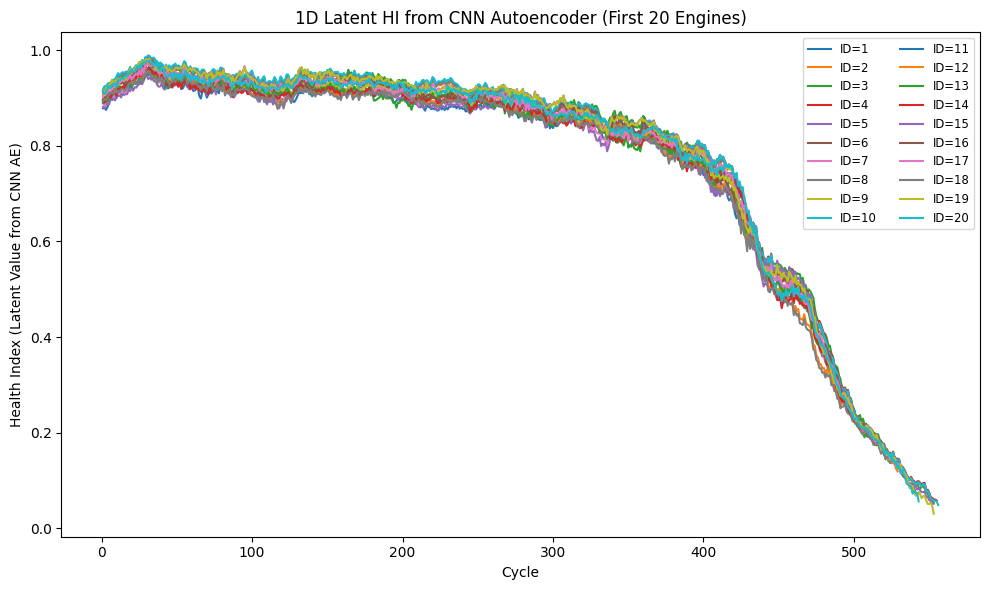

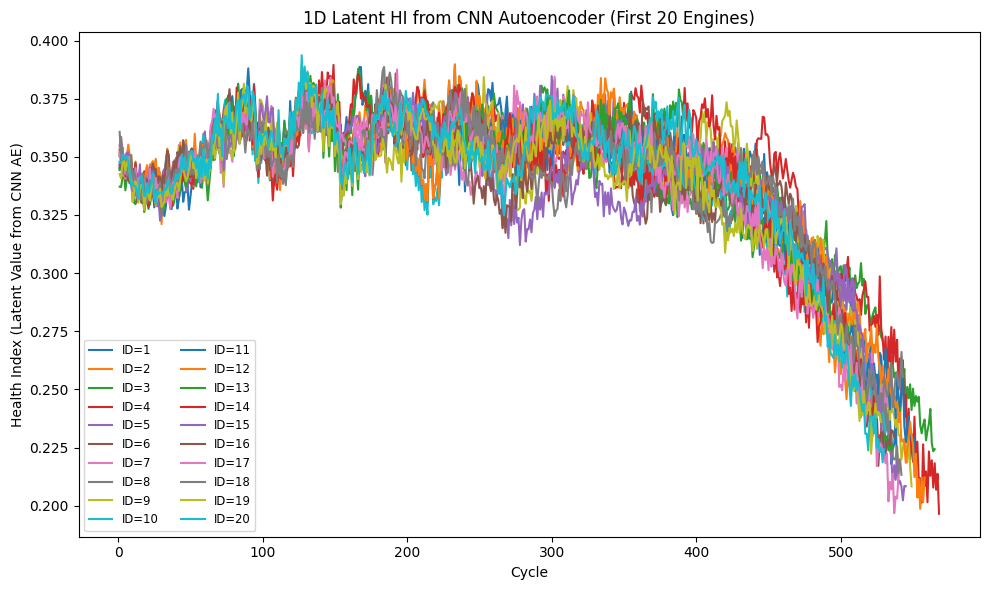

In [31]:
# ==============================
# Extract latent HI values
# ------------------------------
encoder = Model(    inputs  =  cnnAEModel.input,
                    outputs = [cnnAEModel.get_layer('lastAELayer').output, cnnAEModel.get_layer('latent').output],  name="encoder_submodel")
                                                    
_, rawHIValues      = encoder.predict([allXScaled, allEnv])
hiValues            = rawHIValues.flatten()                                                     # Flatten to 1D array
hiValues            = (hiValues - hiValues.min()) / (hiValues.max() - hiValues.min())           # Normalize HI
dfHI                = pd.DataFrame({'env'   : allEnv,
                                    'id'    : allEngineIds,
                                    'cycle' : allBeginningCycles,
                                    'HI'    : hiValues})                                        # Build dataframe for plotting

envDfHI             = {env: group.reset_index(drop=True) for env, group in dfHI.groupby('env')}

drawHI              = envDfHI[1]
# ==============================                
# Plot first 20 engines
# ------------------------------
plt.figure(figsize=(10, 6))
for eng_id in drawHI['id'].unique()[:20]:
    df_eng = drawHI[drawHI['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()

drawHI              = envDfHI[2]
# ==============================                
# Plot first 20 engines
# ------------------------------
plt.figure(figsize=(10, 6))
for eng_id in drawHI['id'].unique()[:20]:
    df_eng = drawHI[drawHI['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


In [ ]:
from prettytable    import PrettyTable

binaryMask, mask_probs = Masking.getMask()
print(binaryMask.shape, mask_probs.shape)

ssTable                 = PrettyTable()
ssTable.field_names     = ["No","sensorName","probability", "binary"]
print(f"The number of selected sensor is {sum(binaryMask)}")
for idx,idxSS in enumerate(sensorUsed):
    ssTable.add_row([idx,idxSS,mask_probs[idx].numpy(),binaryMask[idx].numpy()])

print(ssTable)


### DATA FOR SYSTEM MODEL

In [ ]:
# ========================================
# This function is used to resize the data
# to have the same length between 
# different engines
# ----------------------------------------
def resize_group(g, targetLen, fill_value=0, id_col='trajectoryID', cycle_col='cycle'):
    currentLen  = len(g)
    pad_size    = targetLen - currentLen

    if pad_size == 0:
        return g
    elif pad_size < 0:
        return g.iloc[:targetLen].reset_index(drop=True)

    # Padding case: pad_size > 0
    lastCycle       = g[cycle_col].iloc[-1] if cycle_col in g.columns else currentLen - 1
    pad_df          = pd.DataFrame(fill_value, index=range(pad_size), columns=g.columns)
    pad_df[id_col]  = g[id_col].iloc[0]
    
    if cycle_col in g.columns:
        pad_df[cycle_col] = range(lastCycle + 1, lastCycle + pad_size + 1)

    return pd.concat([g, pad_df], ignore_index=True)


def createSystemData(inData, numberOfTrajectories=300, mode = "max", seed = 2):
    np.random.seed(seed)

    rawData         = inData
    # --------------------------
    # Group the data into ID and
    # initiate the values
    # --------------------------
    grouped_data    = {k: v for k, v in rawData.groupby("engineId")}                                                      # Pre-group `rawData` by 'id' for O(1) lookup
    # createdData     = {}                                                                                                # Initialize dictionary for cases
    # --------------------------
    # Create system data
    # --------------------------
    selected_ids    = np.array([np.random.choice(np.arange(1, 101), size=3, replace=False) for _ in range(numberOfTrajectories)])     # Generate 400 sets of 3 unique trajectory IDs per iteration
    
    comp1_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 0])], ignore_index=True) 
    comp2_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 1])], ignore_index=True) 
    comp3_df        = pd.concat([grouped_data[i].assign(trajectoryID=trajectID + 1) for trajectID, i in enumerate(selected_ids[:, 2])], ignore_index=True)                    # Fetch data from grouped dictionary (guaranteed unique per iteration)
    
    lenEachIDComp1  = comp1_df.groupby("trajectoryID").size()
    lenEachIDComp2  = comp2_df.groupby("trajectoryID").size()
    lenEachIDComp3  = comp3_df.groupby("trajectoryID").size()
    lengths         = pd.concat([lenEachIDComp1, lenEachIDComp2, lenEachIDComp3], axis=1)
    lengths.columns = ['len1', 'len2', 'len3']

    dfRul           = pd.DataFrame(columns=["rul", "trajectoryID"])  
    if mode == 'min':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).min(axis=1)
    
    elif mode == 'max':
        minLen       = lengths.min(axis=1)
        comp1Handled = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"] = pd.concat([comp1Handled["rul"], comp2Handled["rul"], comp3Handled["rul"]], axis=1).max(axis=1)

    else:
        minLen          = lengths.min(axis=1)
        comp1Handled    = comp1_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp2Handled    = comp2_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        comp3Handled    = comp3_df.groupby('trajectoryID').apply(lambda g: g.iloc[:minLen[g.name]]).reset_index(drop=True)
        dfRul["rul"]    = comp1_df["rul"].combine(comp2_df["rul"], max).combine(comp3_df["rul"], min)
        # dfRul.to_excel('output.xlsx', index=False)  # index=False removes the row numbers
    dfRul["comp1"]  = comp1Handled["rul"]
    dfRul["comp2"]  = comp2Handled["rul"]                                                                # Initialize RUL dataframe
    dfRul["comp3"]  = comp3Handled["rul"]
    
    dfRul["trajectoryID"] = comp1Handled["trajectoryID"]      # Add trajectoryID to RUL data
 
    return comp1Handled, comp2Handled, comp3Handled, dfRul, selected_ids

def createRULLabel(inData, mode = "max"):
    if mode == 'min':
        sysRUL = inData.min(axis =2)
    elif mode == 'max':
        sysRUL = inData.max(axis =2)
    else:
        col1 = inData[:,:, 0]
        col2 = inData[:,:, 1]
        col3 = inData[:,:, 2]
        intermediate_max = np.maximum(col1, col2)
        sysRUL = np.minimum(intermediate_max, col3)

    # print(sysRUL.shape, sysRUL[:,-1,:].shape)
    return sysRUL[:,-1]

# ============================
# This function is used to
# get the alightID at the alight 
# position of HI and RUL
# ============================
def getAlightID(rawHIValues,yRul, eng_id, selected_ids):
    rawHIValues = rawHIValues.flatten()     # Flatten to 1D array
    yRul        = yRul.flatten()            # Flatten to 1D array
    matchedID   = []

    # --------------------------------
    # For over the the selectedIds,
    # Then make a comparison of each
    # row of selectedIds, if it follow
    # the order of RUL, get the row of
    # selectedIds
    # --------------------------------
    for orderIdx,idxSelection in enumerate(selected_ids):
        idx1        = idxSelection[0]
        idx2        = idxSelection[1]
        idx3        = idxSelection[2]
        # print(idx1, idx2, idx3)
        # print("---------------------",orderIdx)
        curHI1      = rawHIValues[eng_id == idx1][0]
        curHI2      = rawHIValues[eng_id == idx2][0]
        curHI3      = rawHIValues[eng_id == idx3][0]

        # print(curHI1, curHI2, curHI3)
        
        rul1        = yRul[eng_id == idx1][0]
        rul2        = yRul[eng_id == idx2][0]
        rul3        = yRul[eng_id == idx3][0]

        # print(rul1, rul2, rul3 )
        # -----------------------------
        # Get the order from selected IDs
        # if HI and RUL are in the same order
        # -----------------------------
        if np.argsort([curHI1,curHI2,curHI3]).tolist() == np.argsort([rul1,rul2,rul3]).tolist():  # → True
            matchedID.append(orderIdx+1)
    
    return matchedID
        


### Linear

In [ ]:
# -----------------------------
# Create the system data
# -----------------------------
# print(df.head)
# comp1, comp2, comp3, dfRul, selected_ids    = createSystemData(df, numberOfTrajectories=300, mode=hiSelectionMode, seed = 1)  # Create system data

# xScaled1, engineIds1, beginningCycles1, _, _, _    = dataHandling(comp1,   idName='trajectoryID')
# xScaled2, engineIds2, beginningCycles2, _, _, _    = dataHandling(comp2,   idName='trajectoryID')
# xScaled3, engineIds3, beginningCycles3, _, _, _    = dataHandling(comp3,   idName='trajectoryID')
# allRUL, _, _, _, _, rulScaler                   = dataHandling(dfRul,   idName='trajectoryID', sensorUsed=['comp1', 'comp2', 'comp3'])  # Get RUL data
# sysRUL                                          = createRULLabel(allRUL, mode = hiSelectionMode)
# print(sysRUL.shape)
# print(xScaled1)
# -----------------------------
# Create the alight data to 
# train the HI selection
# -----------------------------
# alightID                                    = getAlightID(rawHIValues, yRul,engineIds,selected_ids)     
# print(alightID)    
# alightComp1                                 = comp1[comp1["trajectoryID"].isin(alightID)]    
# alightComp2                                 = comp2[comp2["trajectoryID"].isin(alightID)] 
# alightComp3                                 = comp3[comp3["trajectoryID"].isin(alightID)]       
# alightRUL                                   = dfRul[dfRul["trajectoryID"].isin(alightID)]  

# alightedInX1, alightedEngineIds1, alightedBeginningCycles1 , _, _, _          = dataHandling(alightComp1,   idName='trajectoryID')
# alightedInX2, alightedEngineIds2, _ , _, _, _          = dataHandling(alightComp2,   idName='trajectoryID')
# alightedInX3, alightedEngineIds3,_ , _, _, _           = dataHandling(alightComp3,   idName='trajectoryID')
# alightedAllRUL, _, _, _, _, _                          = dataHandling(alightRUL,     idName='trajectoryID', sensorUsed=['comp1', 'comp2', 'comp3'], scaler = rulScaler)  # Get RUL data
# alightedSysRUL                                      = createRULLabel(alightedAllRUL, mode = hiSelectionMode)
# print(alightedSysRUL)


#### System

In [ ]:
systemSeed  = 1
sysEpoch    = 30              
tf.random.set_seed(systemSeed)
np.random.seed(systemSeed)
random.seed(systemSeed)


comp1, comp2, comp3, dfRul, selected_ids            = createSystemData(df, numberOfTrajectories=300, mode=hiSelectionMode, seed = systemSeed)  # Create system data

xScaled1, engineIds1, beginningCycles1, _, _, _     = dataHandling(comp1,   idName='trajectoryID')
xScaled2, engineIds2, beginningCycles2, _, _, _     = dataHandling(comp2,   idName='trajectoryID')
xScaled3, engineIds3, beginningCycles3, _, _, _     = dataHandling(comp3,   idName='trajectoryID')
allRUL, _, _, _, _, rulScaler                       = dataHandling(dfRul,   idName='trajectoryID', sensorUsed=['comp1', 'comp2', 'comp3'])  # Get RUL data
sysRUL                                              = createRULLabel(allRUL, mode = hiSelectionMode)
# print(sysRUL.shape)

# ============================
# Freeze the encoder
# ----------------------------
print("==========================")
print("           Encoder          ")
print("==========================")
encoder.summary()
for layer in encoder.layers:
    layer.trainable = False

# ============================
# The loss function for HI selection
# ----------------------------
def selection_entropy_loss(y_true, y_pred):
    """
    y_pred: hiMatrixOutput -> shape (None, 3)
    We ignore y_true because we don't have a label for it.
    This returns the negative sum(p * log p).
    """
    # Add a small constant (1e-10) inside the log to avoid log(0).
    # The shape of this expression is (batch_size,).
    neg_entropy = -tf.reduce_sum(y_pred * tf.math.log(y_pred + 1e-10), axis=-1)
    return neg_entropy



# ===============================
# MODEL
# ===============================
input1              = Input(shape=(seqLength, numFeatures))
input2              = Input(shape=(seqLength, numFeatures))
input3              = Input(shape=(seqLength, numFeatures))

inputRUL1, HI1 = encoder(input1)
inputRUL2, HI2 = encoder(input2)
inputRUL3, HI3 = encoder(input3)


flatInRUL1          = Flatten()(inputRUL1)  # Shape: (32, 40)
flatInRUL2          = Flatten()(inputRUL2)  # Shape: (32, 40)
flatInRUL3          = Flatten()(inputRUL3)  # Shape: (32, 40)
hiSelectionInput    = Concatenate(axis=-1)([flatInRUL1, flatInRUL2, flatInRUL3])

# ------------------------------
# Create the HI selection matrix
# ------------------------------
x                   = Dense(24, activation="relu")(hiSelectionInput)
x                   = Dense(16, activation="relu")(x)
selection_logits    = Dense(3, activation=None, name="Selection_Logits")(x)
hiMatrixOutput      = Lambda(lambda x: tf.nn.softmax(x / 1), name="Selection_Output")(selection_logits)  # Softmax with τ=0.1 for sharper selection

# ------------------------------
# Create min, max and linear HI
# ------------------------------
minSysHi        = Minimum()([HI1, HI2, HI3])
maxSysHi        = Maximum()([HI1, HI2, HI3])
linearSysHi     = Minimum()([Maximum()([HI1, HI2]), HI3])


sysConcatenatedHi   = tf.keras.layers.Concatenate(axis=-1, name="sysConcatenatedHi")([minSysHi, maxSysHi, linearSysHi])
selected_HI         = Multiply(name="Selected_HI")([hiMatrixOutput, sysConcatenatedHi])
sysHi               = Lambda(lambda x: tf.reduce_sum(x, axis=-1, keepdims=True), name="Final_HI")(selected_HI)            # Final HI (ensuring only one HI contributes to output)

# ------------------------------
# RUL
# ------------------------------
concatenatedRULInput    = Concatenate(axis=-1)([inputRUL1, inputRUL2, inputRUL3])
rulLayer1               = LSTM(32, return_sequences=True)(concatenatedRULInput)
rulLayer2               = LSTM(16, return_sequences=True)(rulLayer1)
rulLayer3               = LSTM(3, return_sequences=False)(rulLayer2)
rulLayer4               = Concatenate(axis=-1)([rulLayer3, sysHi])
rul                     = tf.keras.layers.Dense(1, activation='linear', name = "RUL_Output")(rulLayer4)

# ------------------------------
# Create the model
# ------------------------------
sysModel = Model(inputs=[input1, input2, input3], outputs=[hiMatrixOutput, sysHi,rul])

sysModel.compile(optimizer  =       'adam',
                loss        =   {   "Selection_Output"  : selection_entropy_loss,
                                    "Final_HI"          : "mse",
                                    "RUL_Output"        : "mse"},
                loss_weights=   {   "Selection_Output"  : 0.1,  # e.g. a small coefficient
                                    "Final_HI"          : 0.0,  # no label for HI => set to 0 or 0.01 if you want
                                    "RUL_Output"        : 1.0},      
                )
print("==========================")
print("         System MODEL          ")
print("==========================")
sysModel.summary()

dummy_sel = np.zeros_like(sysRUL)
sysModel.fit([xScaled1, xScaled2, xScaled3], [dummy_sel,dummy_sel, sysRUL], epochs=20, batch_size=128, validation_split=0.1, verbose=1)


# [hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])
# print(hiMatrixOutput)



In [ ]:
_, hi_values1   = encoder.predict(xScaled1)
hi_values1      = hi_values1.flatten()  # Flatten to 1D array

_, hi_values2   = encoder.predict(xScaled2)
hi_values2      = hi_values2.flatten()  # Flatten to 1D array

_, hi_values3   = encoder.predict(xScaled3)
hi_values3      = hi_values3.flatten()  # Flatten to 1D array

[hiMatrixOutput, sysHi, rul] = sysModel.predict([xScaled1, xScaled2, xScaled3])

print(hiMatrixOutput)


In [ ]:
# Build dataframe for plotting
dfHI = pd.DataFrame({
    'id'        : engineIds1,
    'cycle'     : beginningCycles1,
    'HI1'       : hi_values1,
    'HI2'       : hi_values2,
    'HI3'       : hi_values3,
    'sysHI'     : sysHi.flatten(),
    "sysRUL"    : rul.flatten(),
    "labelSysRUL": sysRUL.flatten(),
    "comp1RUL": allRUL[:,-1,0].flatten(),
    "comp2RUL": allRUL[:,-1,1].flatten(),
    "comp3RUL": allRUL[:,-1,2].flatten()
})

In [ ]:
import matplotlib.pyplot as plt
import math

num_cols = 5  # number of plots per row
num_rows = math.ceil(drawTrajectories / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax = axes[i]
    df_eng = dfHI[dfHI['id'] == eng_id]
    
    ax.plot(df_eng['cycle'], df_eng["HI1"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["HI2"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["HI3"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["sysHI"], label="Sys")
    
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()


In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = dfHI[dfHI['id'] == eng_id]
    ax.plot(df_eng['cycle'], df_eng["comp1RUL"], label="Comp1")
    ax.plot(df_eng['cycle'], df_eng["comp2RUL"], label="Comp2")
    ax.plot(df_eng['cycle'], df_eng["comp3RUL"], label="Comp3")
    ax.plot(df_eng['cycle'], df_eng["labelSysRUL"], label="CompSys")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)


# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()

In [ ]:
num_cols            = 5  # number of plots per row
num_rows            = math.ceil(drawTrajectories / num_cols)

fig, axes           = plt.subplots(num_rows, num_cols, figsize=(20, num_rows * 2.5), sharex=False, sharey=False)
axes                = axes.flatten()  # Flatten to 1D array for easy indexing

for i, eng_id in enumerate(dfHI['id'].unique()[:drawTrajectories]):
    ax      = axes[i]
    df_eng  = dfHI[dfHI['id'] == eng_id]

    
    ax.plot(df_eng['cycle'], df_eng["sysRUL"], label="Comp1")
    ax.set_title(f"Engine {eng_id}", fontsize=8)
    ax.tick_params(axis='both', labelsize=6)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Add a big legend outside the subplots
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize='small')

fig.suptitle("Health Indices per Engine (1D Latent HI from CNN AE)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for suptitle and legend
plt.show()
